# A code inside a code: Shor's code, levelled up twice

> **In short.**
> * **The idea.** Larger codes are often built by putting a code inside a code. Shor's nine-qubit code is the first example: three *bit-flip codes* (the inner code, one per block of three qubits) and, over the three qubits they store, a *phase-flip code* (the outer code). Each code fixes one kind of error.
> * **The program.** Shor's encoder, one fixed error $E$, then a round for each code: the inner checks and corrections, then the outer checks and corrections.
> * **The levels.** Level 1 groups the inner round, read in the three bit-flip codes. Level 2 groups both rounds, read in Shor's code.
> * **What it shows.** An $X$ is fixed at level 1. A $Z$ passes level 1 as a $Z$ on its block and is fixed at level 2. Two errors in the wrong places fool a round. With rewrites each level draws simpler, down to Shor's encoder alone.
> * **The sections** follow the paper's section *A code inside a code: Shor's code*: (1) the two codes, (2) the program (Fig. 2), (3) levelling up twice, with the codes before and after the level-1 block (Fig. 1), (4) where each error is fixed (Fig. 3), (5) every error (Table 1), (6) seeing the levels (Figs. 4, 5).
> * **Library calls only**: PyZX's OpenQASM reader and `compare_tensors`, `QProgram`, `level_up`, `code_at`, `StabilizerCode.separated`, `logical_action`, `reduced_block`, `reduced_level`, `draw_program`, `view_levels`, `phases_modulo`, `equal_for_all_assignments`.

In [1]:
%matplotlib inline
import pyzx as zx
from IPython.display import display
from pyzx.circuit import Circuit
from pyzx.utils import VertexType
from zxqec.qprogram import QProgram
from zxqec.codes import logical_action
from zxqec.gpf import equal_for_all_assignments, phases_modulo
from zxqec.spacetime import draw_program, get_logical_qubit, view_levels

The program, in OpenQASM. Qubits 0–8 hold the code, in blocks 0–2, 3–5 and 6–8; qubits 9–16 are helpers that measure the checks. Six stages: the encoder, an error $E$ (here $Z_4$), the inner checks, the inner corrections, the outer checks and the outer corrections. Section 2 explains them.

In [2]:
HEADER = """OPENQASM 2.0;
include "qelib1.inc";
qreg q[17];        // data 0-8 (blocks 0-2, 3-5, 6-8); helpers 9-14 inner, 15-16 outer
creg s0[2];        // inner results of block 0
creg s1[2];        // block 1
creg s2[2];        // block 2
creg o[2];         // outer results
"""
ENCODER = ("cx q[0], q[3]; cx q[0], q[6];\nh q[0]; h q[3]; h q[6];\n"
           + "".join("cx q[{0}], q[{1}]; cx q[{0}], q[{2}];\n".format(b, b + 1, b + 2) for b in (0, 3, 6)))
INNER_CHECKS = "".join("cx q[{}], q[{h}]; cx q[{}], q[{h}];\nmeasure q[{h}] -> s{}[{}];\n".format(a, b, k, i, h=9 + 2 * k + i)
                       for k, base in enumerate((0, 3, 6)) for i, (a, b) in enumerate(((base, base + 1), (base + 1, base + 2))))
INNER_CORRECTIONS = "".join("if(s{0}==1) x q[{1}];\nif(s{0}==3) x q[{2}];\nif(s{0}==2) x q[{3}];\n".format(k, b, b + 1, b + 2)
                            for k, b in enumerate((0, 3, 6)))
OUTER_CHECKS = "".join("h q[{h}];\n".format(h=h) + "".join("cx q[{}], q[{}];\n".format(h, d) for d in data)
                       + "h q[{h}];\nmeasure q[{h}] -> o[{i}];\n".format(h=h, i=i)
                       for i, (h, data) in enumerate(((15, range(0, 6)), (16, range(3, 9)))))
OUTER_CORRECTIONS = "if(o==1) z q[0];\nif(o==3) z q[3];\nif(o==2) z q[6];\n"
BLOCKS = [[0, 1, 2], [3, 4, 5], [6, 7, 8]]

programs = {}
QASM = {'X': 'x q[{0}];\n', 'Y': 'z q[{0}]; x q[{0}];\n', 'Z': 'z q[{0}];\n'}
errors = {l + str(q): QASM[l].format(q) for q in range(9) for l in 'XYZ'}
errors.update({'X0X1': 'x q[0];\nx q[1];\n', 'X0X3': 'x q[0];\nx q[3];\n',
               'Z0Z1': 'z q[0];\nz q[1];\n', 'Z0Z3': 'z q[0];\nz q[3];\n'})
for name, text in errors.items():           # one program per error; E = Z4 is the running example
    e = QProgram(17, bits=8, initial_states={q: '0' for q in range(1, 17)})
    for stage, piece in [('encoder', ENCODER), ('error', text), ('inner checks', INNER_CHECKS),
                         ('inner corrections', INNER_CORRECTIONS), ('outer checks', OUTER_CHECKS),
                         ('outer corrections', OUTER_CORRECTIONS)]:
        e.add_circuit(Circuit.from_qasm(HEADER + piece), name=stage)
    programs[name] = e
p = programs['Z4']

## 1. The two codes (Fig. 1)

* **Inner code.** Each block is a *bit-flip code*: it stores one qubit in three, $|0\rangle$ as $|000\rangle$ and $|1\rangle$ as $|111\rangle$, and two checks compare neighbouring qubits ($Z_0Z_1$ and $Z_1Z_2$ in block 0). An $X$ on one qubit makes the checks that contain it return 1. A $Z$ on one qubit is seen by no check: it is a $Z$ on the stored qubit, the logical $Z$ of the block.
* **Outer code.** The three stored qubits form the outer code. Its two checks are $X$ on two whole blocks, $X$ on qubits 0–5 and on qubits 3–8. They see exactly what the inner code misses: a $Z$ on one block.

Question 1 reads Shor's code off the program right after the encoder (`code_at(0)`, Fig. 1a). The helpers are still in $|0\rangle$; `data()` leaves them out. A *stabilizer* is a check: it returns 0 on every state of the code. The tool lists a set of checks that generates them all, so it lists $Z_0Z_2$ where the program measures $Z_1Z_2$.

In [3]:
print("Fig. 1a, Shor's code right after the encoder:")
print(p.code_at(0).data())

Fig. 1a, Shor's code right after the encoder:
[[9, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8
    stabilizer +XXXXXXIII
    stabilizer +XXXIIIXXX
    stabilizer +ZZIIIIIII
    stabilizer +ZIZIIIIII
    stabilizer +IIIZZIIII
    stabilizer +IIIZIZIII
    stabilizer +IIIIIIZZI
    stabilizer +IIIIIIZIZ
    logical X XXXIIIIII   logical Z ZIIZIIZII


**The names of the logical operators.** The tool names them $X = X_0X_1X_2$ and $Z = Z_0Z_3Z_6$. This is a choice of names: the encoder turns a $Z$ on its input into $X_0X_1X_2$ (and an $X$ into $Z_0Z_3Z_6$), so texts that start from the encoder use the opposite names. We use the tool's.

In [4]:
NINE = 'OPENQASM 2.0;\ninclude "qelib1.inc";\nqreg q[9];\n'
for before, after in (('z q[0];\n', 'x q[0]; x q[1]; x q[2];\n'), ('x q[0];\n', 'z q[0]; z q[3]; z q[6];\n')):
    print("{} then the encoder = the encoder then {}: {}".format(before.strip(), after.strip(), zx.compare_tensors(
        Circuit.from_qasm(NINE + before + ENCODER), Circuit.from_qasm(NINE + ENCODER + after), preserve_scalar=True)))

z q[0]; then the encoder = the encoder then x q[0]; x q[1]; x q[2];: True


x q[0]; then the encoder = the encoder then z q[0]; z q[3]; z q[6];: True


## 2. The program (Fig. 2)

* **Inner round.** Helpers 9–14 measure the six inner checks into one two-bit register per block, `s0`, `s1`, `s2`. The inner correction flips the qubit that the two results point to.
* **Outer round.** Helpers 15 and 16 measure the outer checks into `o`, each by a Hadamard, six CNOTs and a Hadamard. The outer correction puts $Z$ on the first qubit of the block that the results point to, which is the logical $Z$ of that block.
* **Reading a register.** A register is read as `c[1]c[0]`, so `s1==1` means that $Z_3Z_4$ returned 1 and $Z_4Z_5$ did not. In the drawing (section 3) a correction is a spider whose phase is its condition, written as a formula in the result bits: `s1==1` is `s1[0] + s1[0]·s1[1]`, which is 1 exactly then.
* **One run.** Each program has one fixed error, so its checks always return the same results.

The corrections, as written (Fig. 2b, c):

In [5]:
print(INNER_CORRECTIONS + OUTER_CORRECTIONS)
print("the circuit:", sum(1 for v in p.quantum_graph().vertices() if p.quantum_graph().type(v) != VertexType.BOUNDARY), "spiders")

if(s0==1) x q[0];
if(s0==3) x q[1];
if(s0==2) x q[2];
if(s1==1) x q[3];
if(s1==3) x q[4];
if(s1==2) x q[5];
if(s2==1) x q[6];
if(s2==3) x q[7];
if(s2==2) x q[8];
if(o==1) z q[0];
if(o==3) z q[3];
if(o==2) z q[6];

the circuit: 116 spiders


## 3. Levelling up twice

Level 1 groups the error, the inner checks and the inner corrections into one block. Question 2 says what a block does to the stored qubits, so it needs a code before the block and a code after it. For level 1 we get both from the program in two steps (Fig. 1):

1. Question 1 reads the code at the cut before the block, right after the encoder (`code_at(0)`), and at the cut after it, right after the inner corrections (`code_at(3)`). Both are Shor's code, which stores one qubit (Fig. 1a, c). After the block the measured helpers are gone, and the checks have signs set by the results. The $-$ on the $X$ check on qubits 0–5 is $Z_4$, which is still there; a sign such as $(-1)^{s0[0]}$ is $+$ here, where every inner result is 0.
2. `StabilizerCode.separated` reads each of the two codes as one code per block. It keeps the six $ZZ$ checks, which lie inside one block, and drops the two $X$ checks, which span two blocks. Nine qubits with six independent checks store $9 - 6 = 3$ qubits, one per block: three bit-flip codes before the block and three after it (Fig. 1b, d). Each string is on its block's three qubits: `ZZI` on qubits 3, 4, 5 is $Z_3Z_4$.

Question 2 on the block, from the three bit-flip codes before it to the three after it, gives a map from three qubits to three, one wire per block.

In [6]:
before = p.code_at(0)                  # step 1: the cut before the block
after = p.code_at(3)                   #         and the cut after it
print("Fig. 1a, before the block, Shor's code:"); print(before.data()); print()
print("Fig. 1b, before the block, three bit-flip codes:")
print(before.separated(BLOCKS + [[q] for q in before.fixed_qubits()]).data()); print()     # step 2
print("Fig. 1c, after the block, Shor's code:"); print(after.data()); print()
print("Fig. 1d, after the block, three bit-flip codes:")
print(after.separated(BLOCKS + [[q] for q in after.fixed_qubits()]).data())

Fig. 1a, before the block, Shor's code:
[[9, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8
    stabilizer +XXXXXXIII
    stabilizer +XXXIIIXXX
    stabilizer +ZZIIIIIII
    stabilizer +ZIZIIIIII
    stabilizer +IIIZZIIII
    stabilizer +IIIZIZIII
    stabilizer +IIIIIIZZI
    stabilizer +IIIIIIZIZ
    logical X XXXIIIIII   logical Z ZIIZIIZII

Fig. 1b, before the block, three bit-flip codes:


[[3, 1, 1]] CSS code on qubits 0, 1, 2
    stabilizer +ZZI
    stabilizer +ZIZ
    logical X XXX   logical Z ZII
[[3, 1, 1]] CSS code on qubits 3, 4, 5
    stabilizer +ZZI
    stabilizer +ZIZ
    logical X XXX   logical Z ZII
[[3, 1, 1]] CSS code on qubits 6, 7, 8
    stabilizer +ZZI
    stabilizer +ZIZ
    logical X XXX   logical Z ZII

Fig. 1c, after the block, Shor's code:
[[9, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8
    stabilizer -XXXXXXIII
    stabilizer +XXXIIIXXX
    stabilizer (-1)^(s0[0])ZZIIIIIII
    stabilizer (-1)^(s0[1])IZZIIIIII
    stabilizer (-1)^(s1[0])IIIZZIIII
    stabilizer (-1)^(s1[1])IIIIZZIII
    stabilizer (-1)^(s2[0])IIIIIIZZI
    stabilizer (-1)^(s2[1])IIIIIIIZZ
    logical X XXXIIIIII   logical Z ZIIZIIZII

Fig. 1d, after the block, three bit-flip codes:
[[3, 1, 1]] CSS code on qubits 0, 1, 2
    stabilizer (-1)^(s0[0])ZZI
    stabilizer (-1)^(s0[1])IZZ
    logical X XXX   logical Z ZII
[[3, 1, 1]] CSS code on qubits 3, 4, 5
    stabilizer (-1)^(

**Why we may read the block this way.** Shor's code is the part of the three bit-flip codes that also passes the two $X$ checks, so every state the program can be in before the block is a state of the larger code. The inner round never uses the $X$ checks: it checks and corrects each block on its own, so it does the same on every state of the larger code, not only on states of Shor's code. And it ends in the larger code again: step 4 of Question 2 confirms that the block keeps the three bit-flip codes, for every error (section 5 checks it). Read this way, the answer says what the inner round did to each block's stored qubit. For $E = Z_4$, in Shor's code the error is only the sign $-$ of an $X$ check. Once that check is dropped, $Z_4$ is the logical $Z$ of block 1, and Question 2 gives $Z$ on block 1 (section 4).

**Level 2** adds the outer round. Question 2 on it reads Shor's code on both sides, right after the encoder and at the end of the program (`code_at(5)`, below: its signs are $+$ in this run, where $o = 3$), and gives a map from one qubit to one: what both rounds did to the one stored qubit.

The drawing is Fig. 2a, the program shaded by the blocks of level 1. A CNOT is a green spider joined to a red spider, a blue edge is a Hadamard, a measurement is a red spider whose phase is its result, and the error is the green $\pi$ on qubit 4. The red spiders in the middle are the inner corrections ($X$), the green ones at the end the outer corrections ($Z$).

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Level 1 (4 blocks):
  Block 0 'encoder': [encoder]
  Block 1 'error + inner round': [error, inner checks, inner corrections]
  Block 2 'outer checks': [outer checks]
  Block 3 'outer corrections': [outer corrections]
Level 2 (2 blocks):
  Block 0 'encoder': [encoder]
  Block 1 'error + both rounds': [error, inner checks, inner corrections, outer checks, outer corrections]
Shor's code at the end of the program:
[[9, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8
    stabilizer (-1)^(o[0] + 1)XXXXXXIII
    stabilizer (-1)^(o[1] + 1)IIIXXXXXX
    stabilizer (-1)^(s0[0])ZZIIIIIII
    stabilizer (-1)^(s0[1])IZZIIIIII
    stabilizer (-1)^(s1[0])IIIZZIIII
    stabilizer (-1)^(s1[1])IIIIZZIII
    stabilizer (-1)^(s2[0])IIIIIIZZI
    stabilizer (-1)^(s2[1])IIIIIIIZZ
    logical X XXXIIIIII   logical Z ZIIZIIZII


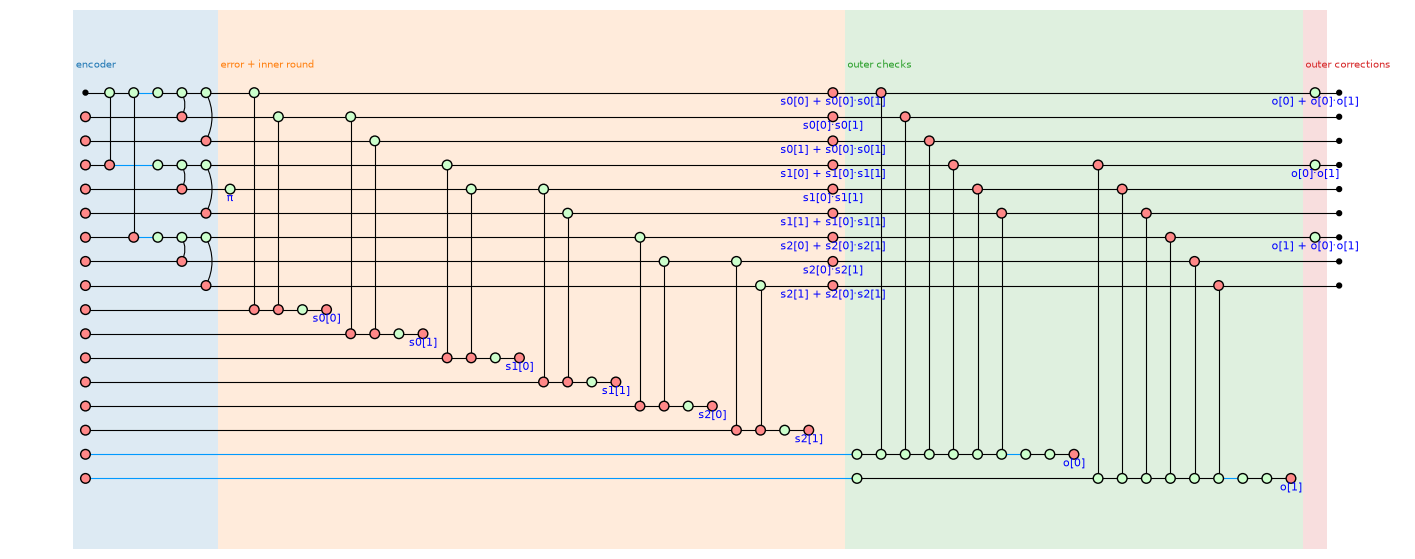

In [7]:
level1 = p.level_up(0, 1, 3, 'error + inner round')            # stages 1-3
level2 = p.level_up(level1, 1, 3, 'error + both rounds')       # blocks 1-3 of level 1
print(p.describe_level(level1))
print(p.describe_level(level2))
print("Shor's code at the end of the program:"); print(p.code_at(5).data())
draw_program(p, level1, time_axis=False, show_time=False, even_rows=True, labels_above=True, figsize=(18, 7))

## 4. Where each error is fixed (Fig. 3)

For each of four errors, Question 2 at level 1 (in the three bit-flip codes: one wire per block, blocks 0–2 from the top) and at level 2 (in Shor's code: one wire). Each picture is drawn with the outcomes modulo the detectors: a plain wire is $I$, a green $\pi$ a $Z$, a red $\pi$ an $X$. Each program has one run; the cell prints its results (the `outcomes` of its one class of runs).

* $X_4$: the two checks of block 1 that contain qubit 4 return 1 (`s1 == 3`), and the inner correction flips qubit 4 back. Fixed at level 1.
* $Z_4$: no check of block 1 sees it, so after level 1 it is a $Z$ on block 1. Both outer checks contain block 1 (`o == 3`), and the outer correction puts $Z$ on block 1. Fixed at level 2.
* $Z_0Z_3$: after level 1, a $Z$ on blocks 0 and 1. The check on qubits 0–5 sees two and returns 0; the one on qubits 3–8 sees one and returns 1 (`o == 2`), as if block 2 had the $Z$. The correction puts $Z$ on block 2, and now all three blocks have one: Shor's logical $Z$, a logical error.
* $X_0X_1$: in block 0 only $Z_1Z_2$ returns 1 (`s0 == 2`), as if qubit 2 were flipped. The correction flips it, and block 0 has $X$ on all three qubits, its logical $X$. The outer checks are made of $X$s and do not see it: at level 2 it is Shor's logical $X$.

E = X4: level 1 leaves III, level 2 leaves I
   results: s0 == 0, s1 == 3, s2 == 0, o == 0


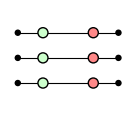

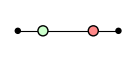

E = Z4: level 1 leaves IZI, level 2 leaves I
   results: s0 == 0, s1 == 0, s2 == 0, o == 3


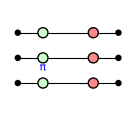

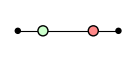

E = Z0Z3: level 1 leaves ZZI, level 2 leaves Z
   results: s0 == 0, s1 == 0, s2 == 0, o == 2


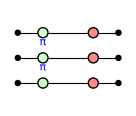

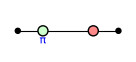

E = X0X1: level 1 leaves XII, level 2 leaves X
   results: s0 == 2, s1 == 0, s2 == 0, o == 0


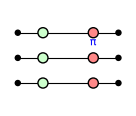

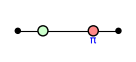

In [8]:
actions = {}
for name, e in programs.items():
    l1 = e.level_up(0, 1, 3, 'error + inner round')
    l2 = e.level_up(l1, 1, 3, 'error + both rounds')
    first = logical_action(e.block_graph(l1, 1, classical=False),
                           e.code_at(0).separated(BLOCKS + [[q] for q in e.code_at(0).fixed_qubits()]),
                           e.code_at(3).separated(BLOCKS + [[q] for q in e.code_at(3).fixed_qubits()]))
    actions[name] = (first, e.logical_action(l2, 1))
for name in ('X4', 'Z4', 'Z0Z3', 'X0X1'):
    first, both = actions[name]
    print("E = {}: level 1 leaves {}, level 2 leaves {}".format(
        name, first.branches()[0].correction or 'III', both.branches()[0].correction or 'I'))
    run = both.branches()[0].outcomes                # the results of the one run
    print("   results:", ", ".join("{} == {}".format(r, run[r + '[0]'] + 2 * run[r + '[1]']) for r in ('s0', 's1', 's2', 'o')))
    display(zx.draw_matplotlib(phases_modulo(first.result.to_graph(), first.result.constraints), figsize=(1.5, 1.25)))
    display(zx.draw_matplotlib(phases_modulo(both.result.to_graph(), both.result.constraints), figsize=(1.5, 0.55)))

## 5. Every error (Table 1)

What is left after each level, for the 27 single-qubit errors and four on two qubits: the Pauli $P$ that `logical_action` names (with $G = I$ in every case). Each program has one fixed error, so all its runs do the same: one class of runs. Then the same results grouped as the rows of Table 1.

In [9]:
rows = {}
print("{:6s} {:8s} {}".format("error", "level 1", "level 2"))
for name, (first, both) in actions.items():
    assert len(first.branches()) == 1 and len(both.branches()) == 1           # one class of runs
    assert {first.branches()[0].operation, both.branches()[0].operation} == {'I'}   # G = I
    assert first.stays_in_code() is True and both.stays_in_code() is True            # step 4, at both levels
    rows[name] = (first.branches()[0].correction or 'III', both.branches()[0].correction or 'I')
    print("{:6s} {:8s} {}".format(name, *rows[name]))
print()
print("every error: one class of runs, G = I, and step 4 holds at both levels")
print("Table 1:")
groups = [("X on any one qubit", ['X' + str(q) for q in range(9)])]
groups += [("Z or Y on a qubit of block {}".format(j), [l + str(q) for q in BLOCKS[j] for l in 'ZY']) for j in range(3)]
groups += [(name, [name]) for name in ('X0X1', 'X0X3', 'Z0Z1', 'Z0Z3')]
for label, names in groups:
    print("{:30s} level 1: {:8s} level 2: {}".format(label, ','.join(sorted({rows[n][0] for n in names})),
                                                    ','.join(sorted({rows[n][1] for n in names}))))

error  level 1  level 2


X0     III      I


Y0     ZII      I


Z0     ZII      I


X1     III      I


Y1     ZII      I
Z1     ZII      I


... (9 outputs left out)

X8     III      I
Y8     IIZ      I


Z8     IIZ      I
X0X1   XII      X


X0X3   III      I
Z0Z1   III      I


Z0Z3   ZZI      Z

every error: one class of runs, G = I, and step 4 holds at both levels
Table 1:
X on any one qubit             level 1: III      level 2: I
Z or Y on a qubit of block 0   level 1: ZII      level 2: I
Z or Y on a qubit of block 1   level 1: IZI      level 2: I
Z or Y on a qubit of block 2   level 1: IIZ      level 2: I
X0X1                           level 1: XII      level 2: X
X0X3                           level 1: III      level 2: I
Z0Z1                           level 1: III      level 2: I
Z0Z3                           level 1: ZZI      level 2: Z


## 6. Seeing the levels (Figs. 4, 5)

Levelling up can also rewrite each block into a smaller diagram with the same meaning (`rewrite='gpf'`, the reduction of Question 2). Here the encoder joins the first block: the helpers are prepared at the start of the program, and a block can remove a helper only if it holds both its preparation and its measurement. (Levelling up again from the stages replaces the levels of section 3.) `equal_for_all_assignments` checks that each level is the same map as the circuit in every run its detectors allow.

In [10]:
rewrite1 = p.level_up(0, 0, 3, 'encoder + error + inner round', rewrite='gpf')
rewrite2 = p.level_up(rewrite1, 0, 2, 'encoder + error + both rounds', rewrite='gpf')
for lv in (rewrite1, rewrite2):
    print(p.describe_reduced(lv))
    reduced = p.reduced_level(lv)
    print("  the same map as the circuit in every allowed run:",
          equal_for_all_assignments(reduced.graph, p.quantum_graph(), constraints=reduced.detectors))

Level 1 (3 blocks), rewritten:
  Block 0: encoder + error + inner round (4 children): 81 spiders -> 14 after rewrite gpf; 6 detector(s) removed here
  Block 1: outer checks (stage 4): 32 spiders -> 32 after no rewrite
  Block 2: outer corrections (stage 5): 3 spiders -> 3 after no rewrite
  the same map as the circuit in every allowed run: True
Level 2 (1 blocks), rewritten:
  Block 0: encoder + error + both rounds (3 children): 49 spiders -> 12 after rewrite gpf; 2 detector(s) removed here
  the same map as the circuit in every allowed run: True


**Level 1 (Fig. 4).** The encoder, $Z_4$ and the inner round, 81 spiders, become 14. The levels view shows the program with the blocks of the level shaded (left), the whole program after the rewrite (middle), the selected block (right) and its size before and after (below).

In the block, three green spiders are joined to a red spider on each qubit: this is Shor's encoder. The cell below lists them: one joined to the input, one to qubits 0–2 and 6–8 (the check $X$ on blocks 0 and 2), and one to qubits 3–8 (the check $X$ on blocks 1 and 2), which carries the $\pi$. The error is still there, as that $\pi$: a $Z$ on qubit 4 flips the sign of every $X$ check that contains qubit 4, and the inner round does not change that. The check on qubits 0–5 is the product of the two, so its sign is $-$ too: both outer checks will return 1. The two red spiders on qubits 15 and 16 are the outer helpers, still in $|0\rangle$.

green spider: joined to the red spiders of qubits [0, 1, 2, 6, 7, 8]
green spider with phase pi: joined to the red spiders of qubits [3, 4, 5, 6, 7, 8]
green spider: joined to the input, joined to the red spiders of qubits [6, 7, 8]


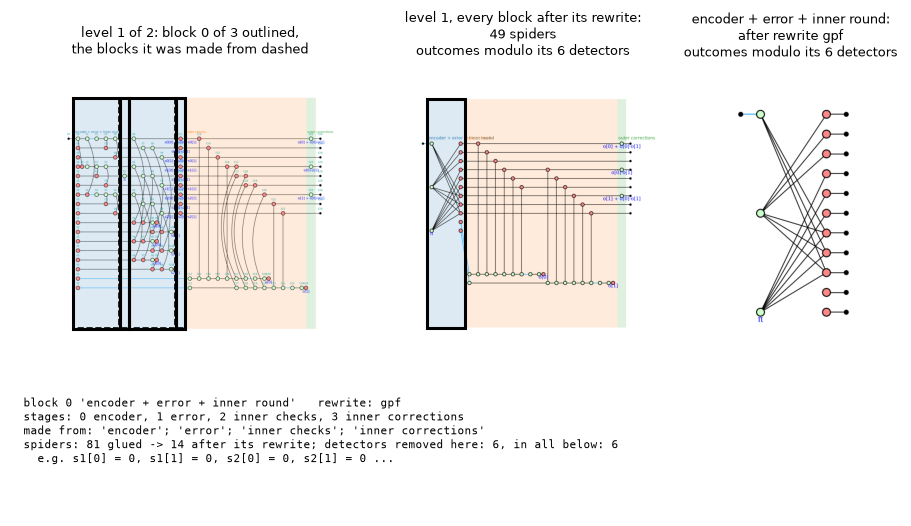

In [11]:
block = p.reduced_block(rewrite1, 0).graph
qubit_of = {}
for b in block.outputs():
    (r,) = block.neighbors(b)
    qubit_of[r] = get_logical_qubit(block, b)
for v in block.vertices():
    if block.type(v) == VertexType.Z:
        print("green spider{}: {}joined to the red spiders of qubits {}".format(
            " with phase pi" if block.phase(v) == 1 else "", "joined to the input, " if any(u in block.inputs() for u in block.neighbors(v)) else "",
            sorted(qubit_of[u] for u in block.neighbors(v) if u in qubit_of)))
view = view_levels(p, rewrite1, 0, controls=False, figsize=(9, 5.2), program_figsize=(12, 10), level_figsize=(7, 7), block_figsize=(3, 4))

**Level 2 (Fig. 5).** Everything becomes 12 spiders, Shor's encoder with no $\pi$: the error is gone. It is the same map as the nine-qubit encoder alone, in every run the detectors allow (the outer results, $o_0 = o_1 = 1$).

level 2 is the same map as Shor's encoder: True


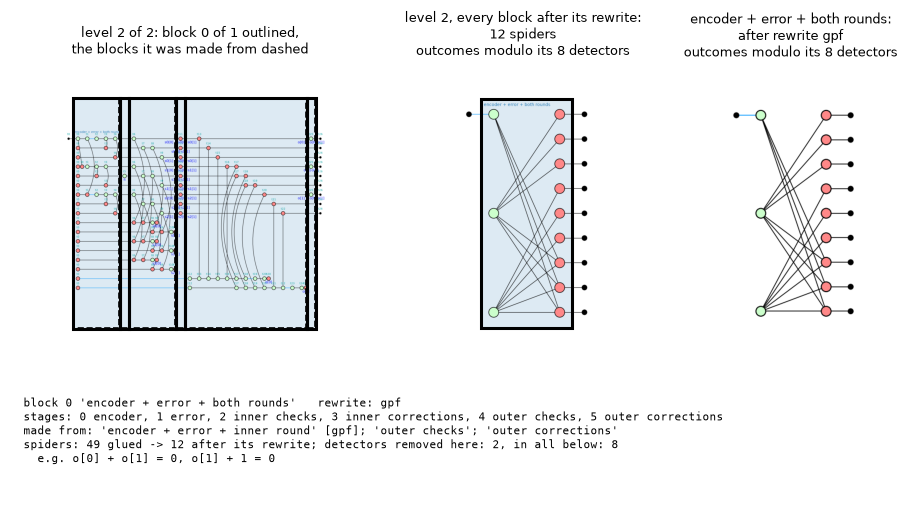

In [12]:
encoder_only = QProgram(9, initial_states={q: '0' for q in range(1, 9)})
encoder_only.add_circuit(Circuit.from_qasm(NINE + ENCODER), name='encoder')
print("level 2 is the same map as Shor's encoder:",
      equal_for_all_assignments(p.reduced_level(rewrite2).graph, encoder_only.quantum_graph(),
                                constraints=p.reduced_level(rewrite2).detectors))
view = view_levels(p, rewrite2, 0, controls=False, figsize=(9, 5.2), program_figsize=(12, 10), level_figsize=(7, 7), block_figsize=(3, 4))

## In short

Levels let us read one program one code at a time. The tool's answers show how Shor's code works: a $Z$ that the inner code cannot fix becomes, one level up, an error on one qubit of the outer code, and the outer code fixes it.